In [12]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning, module='numpy')
from src.preprocessing import split_columns, best_f1_threshold

d = joblib.load('../Data/processed/split.joblib')
X_train, y_train, g_train = d['X_train'], d['y_train'], d['g_train']
num_cols, cat_cols = split_columns(X_train)
FIG = '../reports/figures/' 
print('done')

done


In [13]:
preprocess_rf = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

rf_pipe = Pipeline([
    ('pre', preprocess_rf),
    ('clf', RandomForestClassifier(class_weight='balanced_subsample', random_state=42, n_jobs=-1)),
]) 

In [14]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
param_dist = {
    'clf__n_estimators': [200, 300, 500],
    'clf__max_depth': [10, 15, 20, None],
    'clf__min_samples_leaf': [1, 5, 10, 20],
    'clf__max_features': ['sqrt', 0.3],
}

rf_search = RandomizedSearchCV(rf_pipe, param_dist, n_iter=15, cv=cv, scoring='average_precision', n_jobs=-1, random_state=42, return_train_score=True, verbose=2)
rf_search.fit(X_train, y_train, groups=g_train)

print('Best params:', rf_search.best_params_)
print('Best CV PR-AUC: {:.4f}'.format(rf_search.best_score_))
print('Refit time: {:.1f}s'.format(rf_search.refit_time_))

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best params: {'clf__n_estimators': 300, 'clf__min_samples_leaf': 20, 'clf__max_features': 0.3, 'clf__max_depth': None}
Best CV PR-AUC: 0.2118
Refit time: 28.2s


In [15]:
res = pd.DataFrame(rf_search.cv_results_)
res = res[['params', 'mean_train_score', 'mean_test_score']].sort_values(
    'mean_test_score', ascending=False)
res['gap'] = res['mean_train_score'] - res['mean_test_score']
res.head(10)

,params,mean_train_score,mean_test_score,gap
3,"{'clf__n_estimators': 300, 'clf__min_samples_l...",0.530777,0.211831,0.318947
6,"{'clf__n_estimators': 200, 'clf__min_samples_l...",0.512342,0.211497,0.300845
0,"{'clf__n_estimators': 500, 'clf__min_samples_l...",0.696875,0.210726,0.486149
5,"{'clf__n_estimators': 300, 'clf__min_samples_l...",0.693595,0.210535,0.483060
4,"{'clf__n_estimators': 200, 'clf__min_samples_l...",0.385334,0.210200,0.175133
12,"{'clf__n_estimators': 200, 'clf__min_samples_l...",0.359855,0.209604,0.150251
1,"{'clf__n_estimators': 500, 'clf__min_samples_l...",0.950547,0.209111,0.741436
7,"{'clf__n_estimators': 200, 'clf__min_samples_l...",0.599636,0.208800,0.390836
14,"{'clf__n_estimators': 300, 'clf__min_samples_l...",0.503634,0.208510,0.295123
9,"{'clf__n_estimators': 300, 'clf__min_samples_l...",0.294505,0.208147,0.086358


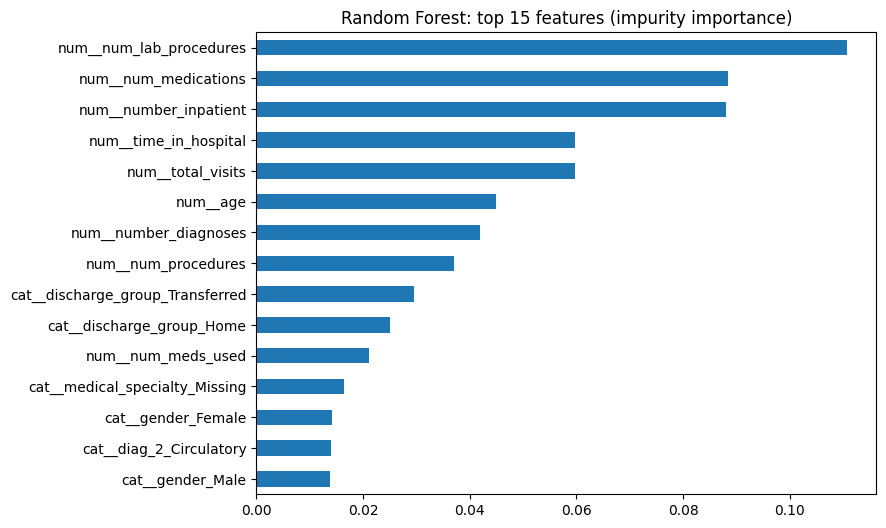

In [16]:
best_rf = rf_search.best_estimator_
names = best_rf.named_steps['pre'].get_feature_names_out()
imp = pd.Series(best_rf.named_steps['clf'].feature_importances_, index=names)
imp.sort_values().tail(15).plot(kind='barh', figsize=(8, 6))
plt.title('Random Forest: top 15 features (impurity importance)')
plt.savefig(FIG + '04_rf_importance.png', dpi=150, bbox_inches='tight')
plt.show()

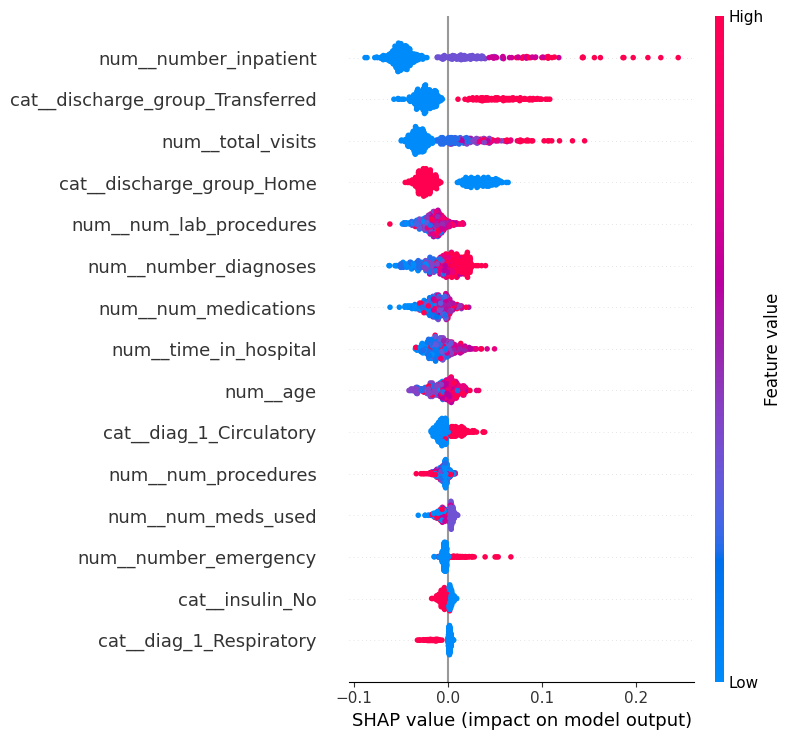

In [21]:
import shap

pre = best_rf.named_steps['pre']
sample = X_train.sample(500, random_state=42)
Xs = pre.transform(sample)
if hasattr(Xs, 'toarray'):
    Xs = Xs.toarray()

explainer = shap.TreeExplainer(best_rf.named_steps['clf'])
sv = explainer.shap_values(Xs)
# different shap versions return different shapes for binary models
if isinstance(sv, list):
    sv = sv[1]
elif sv.ndim == 3:
    sv = sv[:, :, 1]

shap.summary_plot(sv, Xs, feature_names=names, max_display=15, show=False)
plt.savefig(FIG + '04_rf_shap.png', dpi=150, bbox_inches='tight')
plt.show()

In [22]:
oof_rf = cross_val_predict(best_rf, X_train, y_train, groups=g_train,
                           cv=cv, method='predict_proba')[:, 1]
rf_threshold, rf_f1 = best_f1_threshold(y_train, oof_rf)
print(f'Chosen threshold: {rf_threshold:.3f} (OOF F1 = {rf_f1:.3f})')

Chosen threshold: 0.433 (OOF F1 = 0.276)


In [23]:
joblib.dump({'model': best_rf, 'threshold': rf_threshold, 'refit_time': rf_search.refit_time_}, '../models/randomforest.joblib')

['../models/randomforest.joblib']